# 01 · Análisis exploratorio (EDA)

**Objetivo de negocio:** una aseguradora de salud quiere ofrecer seguro de vehículo a su cartera. Contactar a todos es caro, así que necesitamos **ordenar a los clientes por probabilidad de interés**.

**Qué buscamos en este notebook:**

1. ¿Los datos son fiables? (nulos, duplicados, tipos, valores raros)
2. ¿Cómo de desbalanceado está el target?
3. ¿Qué variables separan a los interesados y cuáles no aportan?
4. ¿Qué decisiones de modelado se derivan de lo anterior?

Solo se usa `train.csv`: el `test.csv` de Kaggle no trae etiqueta y no se puede evaluar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from xsell.data import TARGET, load_data

DATA_PATH = Path("../data/raw/train.csv")

# Estilo común de los gráficos: un solo color, ejes discretos.
BLUE = "#2a78d6"
GREY = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Carga y calidad del dato

In [2]:
df = load_data(DATA_PATH)  # ya valida columnas, nulos, ids únicos y target binario
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head()

381,109 filas x 12 columnas


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28,0,> 2 Years,Yes,"40,454.000",26,217,1
1,2,Male,76,1,3,0,1-2 Year,No,"33,536.000",26,183,0
2,3,Male,47,1,28,0,> 2 Years,Yes,"38,294.000",26,27,1
3,4,Male,21,1,11,1,< 1 Year,No,"28,619.000",152,203,0
4,5,Female,29,1,41,1,< 1 Year,No,"27,496.000",152,39,0


In [3]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
})
resumen

,tipo,nulos,valores_distintos
id,int64,0,381109
Gender,str,0,2
Age,int64,0,66
Driving_License,int64,0,2
Region_Code,int64,0,53
Previously_Insured,int64,0,2
Vehicle_Age,str,0,3
Vehicle_Damage,str,0,2
Annual_Premium,float64,0,48838
Policy_Sales_Channel,int64,0,155


In [4]:
# Filas idénticas en todo salvo el id: ¿clientes repetidos o simple coincidencia?
dup = df.drop(columns="id").duplicated().sum()
print(f"Filas duplicadas ignorando el id: {dup} ({dup / len(df):.2%})")

Filas duplicadas ignorando el id: 269 (0.07%)


**Lectura:**

- Sin nulos y sin ids repetidos. No hace falta imputación.
- Hay 269 filas idénticas salvo el `id` (0,07 %). Con variables tan discretas es compatible con coincidencias entre clientes distintos, así que **se mantienen**.
- `Region_Code` y `Policy_Sales_Channel` son números, pero son **códigos** (categorías), no magnitudes. `load_data` los deja como enteros y más adelante se tratan como categóricas.

## 2. Target

In [5]:
tasa_global = df[TARGET].mean()
print(f"Clientes interesados: {df[TARGET].sum():,} de {len(df):,} ({tasa_global:.2%})")

Clientes interesados: 46,710 de 381,109 (12.26%)


**Lectura:** solo un 12,3 % de interesados. Consecuencias:

- **Accuracy no sirve**: un modelo que diga siempre "no" acierta el 87,7 %.
- El problema es de **ranking** (a quién llamo primero). Las métricas serán PR-AUC y lift / captura por deciles.
- Los splits tienen que ser **estratificados** para conservar ese 12,3 % en cada parte.

## 3. Relación de cada variable con el target

Para cada variable miramos dos cosas a la vez: **cuántos clientes** hay en cada valor y **qué porcentaje está interesado**. Una tasa muy alta sobre muy pocos clientes importa poco.

In [6]:
def tasa_por(col):
    """Tabla con nº de clientes, peso en la cartera y tasa de interés por valor de `col`."""
    t = df.groupby(col)[TARGET].agg(clientes="size", tasa_interes="mean")
    t["pct_cartera"] = t["clientes"] / len(df)
    return t[["clientes", "pct_cartera", "tasa_interes"]]


def plot_tasa(tabla, titulo, ax):
    """Barras horizontales con la tasa de interés; la línea discontinua es la tasa global."""
    etiquetas = tabla.index.astype(str)
    ax.barh(etiquetas, tabla["tasa_interes"], color=BLUE, height=0.6)
    ax.axvline(tasa_global, color=GREY, linestyle="--", linewidth=1)
    for y, v in enumerate(tabla["tasa_interes"]):
        ax.text(v, y, f" {v:.1%}", va="center", fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.grid(axis="y", visible=False)
    ax.invert_yaxis()

### 3.1 Variables binarias y de pocas categorías

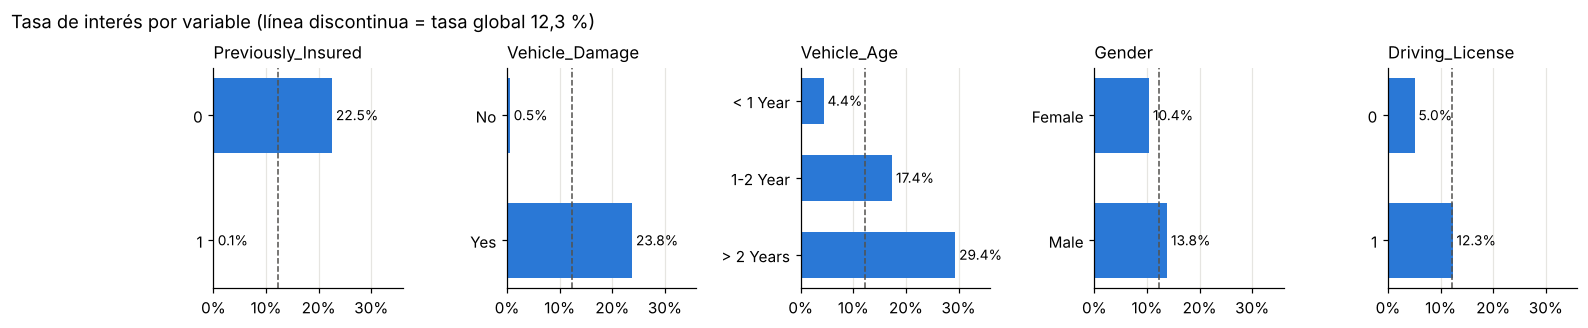

,clientes,pct_cartera,tasa_interes
Previously_Insured,,,
0,206481,0.542,0.225
1,174628,0.458,0.001


,clientes,pct_cartera,tasa_interes
Vehicle_Damage,,,
No,188696,0.495,0.005
Yes,192413,0.505,0.238


,clientes,pct_cartera,tasa_interes
Vehicle_Age,,,
< 1 Year,164786,0.432,0.044
1-2 Year,200316,0.526,0.174
> 2 Years,16007,0.042,0.294


,clientes,pct_cartera,tasa_interes
Gender,,,
Female,175020,0.459,0.104
Male,206089,0.541,0.138


,clientes,pct_cartera,tasa_interes
Driving_License,,,
0,812,0.002,0.050
1,380297,0.998,0.123


In [7]:
cols = ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Gender", "Driving_License"]

ORDEN_VEHICLE_AGE = ["< 1 Year", "1-2 Year", "> 2 Years"]  # orden natural, no alfabético

tablas = {col: tasa_por(col) for col in cols}
tablas["Vehicle_Age"] = tablas["Vehicle_Age"].loc[ORDEN_VEHICLE_AGE]

fig, axes = plt.subplots(1, len(cols), figsize=(16, 2.6), sharex=True)
for col, ax in zip(cols, axes):
    plot_tasa(tablas[col], col, ax)
    ax.set_xlim(0, 0.36)
fig.subplots_adjust(wspace=0.55)
fig.suptitle("Tasa de interés por variable (línea discontinua = tasa global 12,3 %)", x=0.01, ha="left", y=1.08)
plt.show()

for col in cols:
    display(tablas[col])

**Lectura:**

- **`Previously_Insured`** es la variable más determinante: quien ya tiene seguro de vehículo casi nunca está interesado (0,09 %). Son el 46 % de la cartera.
- **`Vehicle_Damage`**: sin daños previos el interés es del 0,5 %; con daños, del 23,8 %.
- **`Vehicle_Age`**: a más antigüedad, más interés (4,4 % → 17,4 % → 29,4 %). Tiene orden natural, así que se puede codificar como ordinal.
- **`Gender`**: diferencia moderada (13,8 % vs 10,4 %). Ver la nota de la sección 5.
- **`Driving_License`**: el 99,8 % tiene carnet. Variable casi constante, aporta muy poco.

### 3.2 Las dos variables fuertes, combinadas

In [8]:
cruce = df.groupby(["Previously_Insured", "Vehicle_Damage"])[TARGET].agg(
    clientes="size", interesados="sum", tasa_interes="mean"
)
cruce["pct_cartera"] = cruce["clientes"] / len(df)
cruce["pct_interesados"] = cruce["interesados"] / df[TARGET].sum()
cruce

clientes  interesados  tasa_interes  \
Previously_Insured Vehicle_Damage                                        
0                  No                 23990          910         0.038   
                   Yes               182491        45642         0.250   
1                  No                164706           72         0.000   
                   Yes                 9922           86         0.009   

                                   pct_cartera  pct_interesados  
Previously_Insured Vehicle_Damage                                
0                  No                    0.063            0.019  
                   Yes                   0.479            0.977  
1                  No                    0.432            0.002  
                   Yes                   0.026            0.002

**Lectura (el hallazgo principal del EDA):** el segmento **"sin seguro de vehículo y con daños previos"** es el 48 % de la cartera y concentra el **97,7 % de los interesados**, con una tasa del 25 %.

Esto condiciona todo lo demás:

- Una **regla de negocio** de una línea ya descarta media cartera perdiendo solo un 2,3 % de interesados. Ese es el **baseline que hay que batir**, no el azar.
- El valor del modelo está en **ordenar dentro de ese segmento** (donde 3 de cada 4 siguen sin estar interesados).
- No parece fuga de información: ambas variables se conocen antes de hacer la oferta y tienen sentido de negocio (quien ya está asegurado no necesita otro seguro; quien ha tenido un siniestro valora más estar cubierto).

### 3.3 Edad

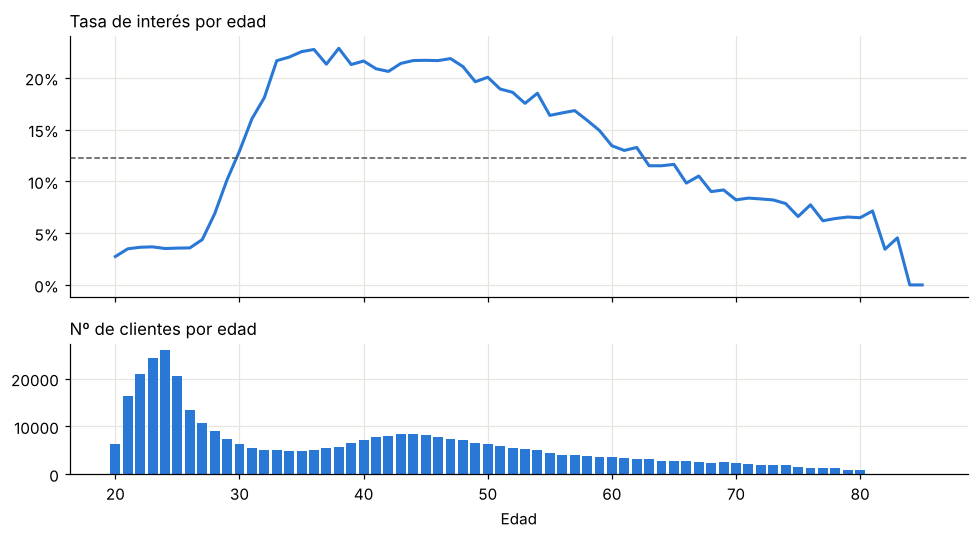

In [9]:
por_edad = df.groupby("Age")[TARGET].agg(clientes="size", tasa_interes="mean")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, height_ratios=[2, 1])
ax1.plot(por_edad.index, por_edad["tasa_interes"], color=BLUE, linewidth=2)
ax1.axhline(tasa_global, color=GREY, linestyle="--", linewidth=1)
ax1.set_title("Tasa de interés por edad", loc="left", fontsize=11)
ax1.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax2.bar(por_edad.index, por_edad["clientes"], color=BLUE, width=0.8)
ax2.set_title("Nº de clientes por edad", loc="left", fontsize=11)
ax2.set_xlabel("Edad")
plt.tight_layout()
plt.show()

**Lectura:** la relación **no es lineal**: muy baja hasta los 25 años (~3,5 %), máxima entre 30 y 50 (~21 %) y cae de nuevo a partir de 60. Además hay muchísimos clientes muy jóvenes.

- Un modelo lineal con la edad "tal cual" no puede capturar esta forma de U invertida: necesitaría tramos. Un modelo de árboles la captura sola.
- En las colas (más de 75 años) hay pocos clientes y la tasa es ruidosa.

### 3.4 Variables de alta cardinalidad: región y canal de venta

In [10]:
for col in ["Region_Code", "Policy_Sales_Channel"]:
    t = tasa_por(col).sort_values("clientes", ascending=False)
    pocos = (t["clientes"] < 100).sum()
    print(f"{col}: {len(t)} valores distintos, {pocos} con menos de 100 clientes")
    display(t.head(6))

Region_Code: 53 valores distintos, 0 con menos de 100 clientes


,clientes,pct_cartera,tasa_interes
Region_Code,,,
28,106415,0.279,0.187
8,33877,0.089,0.096
46,19749,0.052,0.103
41,18263,0.048,0.122
15,13308,0.035,0.072
30,12191,0.032,0.074


Policy_Sales_Channel: 155 valores distintos, 92 con menos de 100 clientes


,clientes,pct_cartera,tasa_interes
Policy_Sales_Channel,,,
152,134784,0.354,0.029
26,79700,0.209,0.199
124,73995,0.194,0.189
160,21779,0.057,0.022
156,10661,0.028,0.215
122,9930,0.026,0.173


**Lectura:**

- **`Policy_Sales_Channel`**: 155 canales, pero 3 de ellos (152, 26 y 124) concentran el 76 % de los clientes y **92 canales tienen menos de 100**. Las tasas son muy distintas entre canales grandes (2,9 % en el 152 frente a ~19-20 % en el 26 y el 124).
- **`Region_Code`**: 53 regiones; la 28 tiene el 28 % de la cartera y una tasa alta (18,7 %).
- **Decisión:** tratarlas como categóricas y **agrupar los valores poco frecuentes** en una categoría "otros". Así se evita aprender tasas de 20 clientes y el modelo sabe qué hacer con un canal nuevo en producción.
- **Ojo con el canal:** está muy correlacionado con la edad (el 152 es un canal de clientes jóvenes). Parte de su efecto es el de la edad.

In [11]:
# Comprobación de la última afirmación: edad mediana en los canales grandes
df.groupby("Policy_Sales_Channel")["Age"].agg(clientes="size", edad_mediana="median").sort_values(
    "clientes", ascending=False
).head(5)

,clientes,edad_mediana
Policy_Sales_Channel,,
152,134784,25.000
26,79700,49.000
124,73995,45.000
160,21779,21.000
156,10661,37.000


### 3.5 Prima anual

Prima mínima: 2,630  ->  17.0% de los clientes tienen exactamente ese valor
Percentil 99: 72,963   Máximo: 540,165


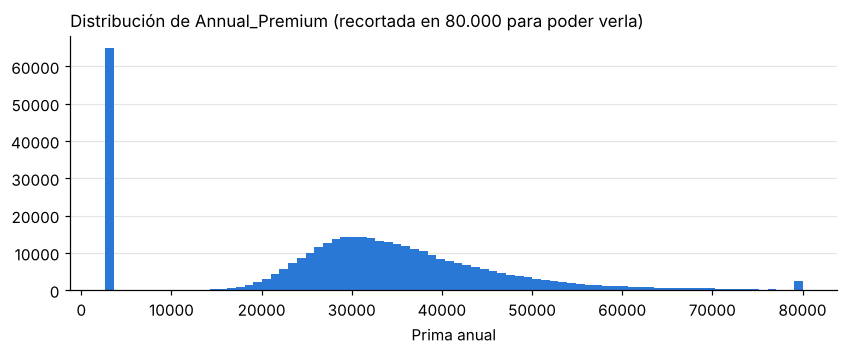

,clientes,tasa_interes
Annual_Premium,,
"(2629.999, 21583.6]",76222,0.124
"(21583.6, 29082.0]",76236,0.099
"(29082.0, 34406.0]",76214,0.112
"(34406.0, 41711.0]",76217,0.130
"(41711.0, 540165.0]",76220,0.148


In [12]:
prima_min = df["Annual_Premium"].min()
en_min = (df["Annual_Premium"] == prima_min).mean()
print(f"Prima mínima: {prima_min:,.0f}  ->  {en_min:.1%} de los clientes tienen exactamente ese valor")
print(f"Percentil 99: {df['Annual_Premium'].quantile(0.99):,.0f}   Máximo: {df['Annual_Premium'].max():,.0f}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(df["Annual_Premium"].clip(upper=80_000), bins=80, color=BLUE)
ax.set_title("Distribución de Annual_Premium (recortada en 80.000 para poder verla)", loc="left", fontsize=11)
ax.set_xlabel("Prima anual")
ax.grid(axis="x", visible=False)
plt.show()

tramos = pd.qcut(df["Annual_Premium"], 5, duplicates="drop")
df.groupby(tramos, observed=True)[TARGET].agg(clientes="size", tasa_interes="mean")

**Lectura:**

- El 17 % de los clientes tiene exactamente **2.630**: parece una prima mínima o un valor por defecto, no una prima "real". Es una pregunta para negocio.
- Cola muy larga (máximo 540.000, percentil 99 en 73.000). Con modelos de árboles no molesta; con un modelo lineal habría que recortar o transformar.
- Relación débil con el target (entre 10 % y 15 % según el tramo).

### 3.6 Antigüedad como cliente (`Vintage`)

In [13]:
tramos = pd.qcut(df["Vintage"], 10)
df.groupby(tramos, observed=True)[TARGET].agg(clientes="size", tasa_interes="mean")

,clientes,tasa_interes
Vintage,,
"(9.999, 38.0]",38164,0.124
"(38.0, 68.0]",39344,0.124
"(68.0, 96.0]",37088,0.119
"(96.0, 125.0]",38213,0.121
"(125.0, 154.0]",38151,0.125
"(154.0, 183.0]",37797,0.121
"(183.0, 212.0]",38150,0.125
"(212.0, 241.0]",38080,0.123
"(241.0, 270.0]",38281,0.120


**Lectura:** la tasa es plana (~12 %) en todos los tramos y la distribución de `Vintage` es uniforme. **No aporta señal**; se excluye del modelo. Menos variables = menos cosas que mantener y monitorizar.

## 4. ¿Cuánto consigue una regla sin modelo?

Antes de entrenar nada, medimos el baseline de negocio: contactar solo al segmento "sin seguro y con daños previos".

In [14]:
regla = (df["Previously_Insured"] == 0) & (df["Vehicle_Damage"] == "Yes")

contactados = regla.mean()
precision = df.loc[regla, TARGET].mean()
captura = df.loc[regla, TARGET].sum() / df[TARGET].sum()

print(f"Clientes contactados:        {contactados:.1%} de la cartera")
print(f"Interesados entre ellos:     {precision:.1%}  (lift {precision / tasa_global:.2f}x sobre contactar al azar)")
print(f"Interesados capturados:      {captura:.1%} del total")

Clientes contactados:        47.9% de la cartera
Interesados entre ellos:     25.0%  (lift 2.04x sobre contactar al azar)
Interesados capturados:      97.7% del total


## 5. Conclusiones y decisiones para el modelado

| Hallazgo | Decisión |
|---|---|
| Target al 12,3 % | Métricas de ranking (PR-AUC, lift y captura por deciles). Splits estratificados. |
| Una regla simple captura el 97,7 % de interesados contactando al 48 % | La regla es el **baseline a batir**. El modelo se juzga por cuánto mejora a igual volumen de contactos. |
| Edad con relación no lineal | Modelo de árboles (gradient boosting) como candidato principal; regresión logística como referencia interpretable. |
| Región y canal con muchas categorías raras | Categóricas, agrupando las poco frecuentes en "otros". |
| `Vehicle_Age` tiene orden | Codificación ordinal. |
| `Vintage` sin señal, `id` es un identificador | Fuera del modelo. |
| `Driving_License` casi constante | Se mantiene de momento; candidata a eliminar si no aporta. |
| `Annual_Premium` con pico en 2.630 y cola larga | Sin transformar para árboles; pregunta abierta para negocio sobre el 2.630. |

**Nota sobre `Gender`:** en la UE no se permite usar el sexo para calcular primas de seguros. Aquí se usaría para priorizar contactos comerciales, no para fijar precios, pero es una variable sensible. Se medirá cuánto aporta al modelo y, si la ganancia es pequeña, se dejará fuera.

**Preguntas que haría a negocio:**

- ¿Qué significa una prima de 2.630? ¿Es un producto distinto?
- ¿En qué momento se recogió `Response` y cómo (encuesta, llamada)? Determina si el modelo predice "interés declarado" o "contratación".
- ¿Cuánto cuesta un contacto y cuánto vale una póliza? Con eso se fija el punto de corte óptimo en vez de un umbral arbitrario.